# 03. Transformer-based comparisons
Transformer (from scratch), ViT (HF `google/vit-base-patch16-224-in21k`) and CLIP on the same data split.

## Transformer (from scratch)

Epoch 1/100
   2217/Unknown 64s 15ms/step - accuracy: 0.1459 - loss: 0.4047

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2219/2219 ━━━━━━━━━━━━━━━━━━━━ 69s 17ms/step - accuracy: 0.1459 - loss: 0.4047 - val_accuracy: 0.1558 - val_loss: 0.3657 - learning_rate: 5.0000e-04
Epoch 2/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.1517 - loss: 0.3654 - val_accuracy: 0.1561 - val_loss: 0.3623 - learning_rate: 5.0000e-04
Epoch 3/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.1566 - loss: 0.3619 - val_accuracy: 0.1610 - val_loss: 0.3614 - learning_rate: 5.0000e-04
...
Epoch 30/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.3739 - loss: 0.2860 - val_accuracy: 0.3770 - val_loss: 0.2896 - learning_rate: 5.0000e-04
Epoch 31/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 19s 7ms/step - accuracy: 0.3761 - loss: 0.2834 - val_accuracy: 0.3691 - val_loss: 0.2956 - learning_rate: 5.0000e-04
Epoch 32/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 18s 7ms/step - accuracy: 0.3931 - loss: 0.2749 - val_accuracy: 0.3920 - val_loss: 0.2843 - learning_rate: 2.5000e-04
Epoch 33/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_47
Received: inputs=('Tensor(shape=(32, 64, 64, 1))',)
  warnings.warn(msg)


133/149 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_47
Received: inputs=('Tensor(shape=(None, 64, 64, 1))',)
  warnings.warn(msg)


149/149 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step
Accuracy for happy: 0.79
Accuracy for sad: 0.25
Accuracy for anger: 0.33
Accuracy for surprise: 0.55
Accuracy for disgust: 0.13
Accuracy for neutral: 0.57
Accuracy for fear: 0.10
Precision: 0.36
Recall: 0.39
F1 Score: 0.36
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Transformer Only ROC AUC Score: 0.75


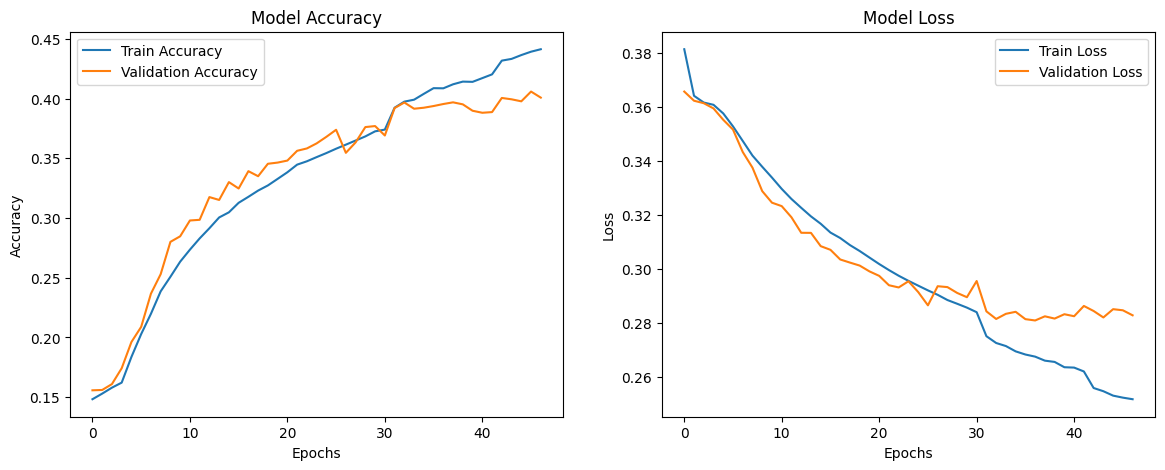

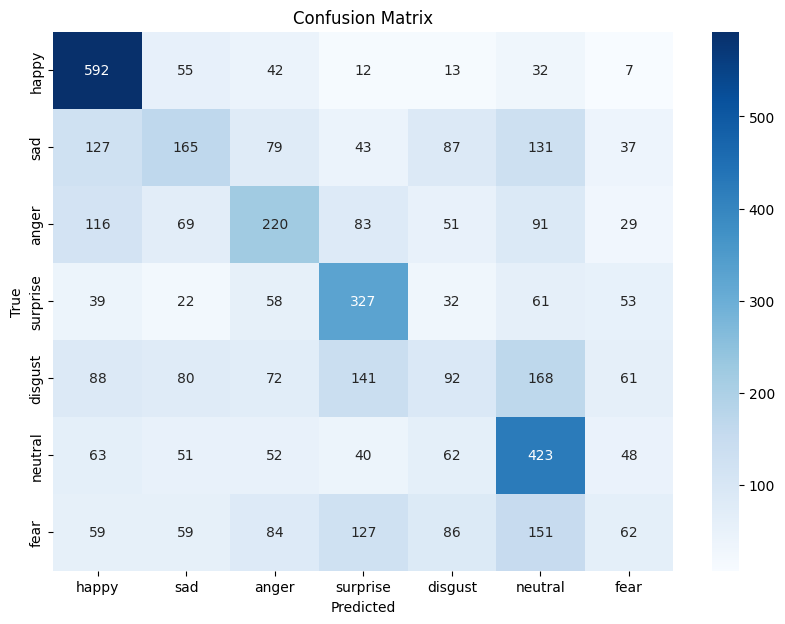

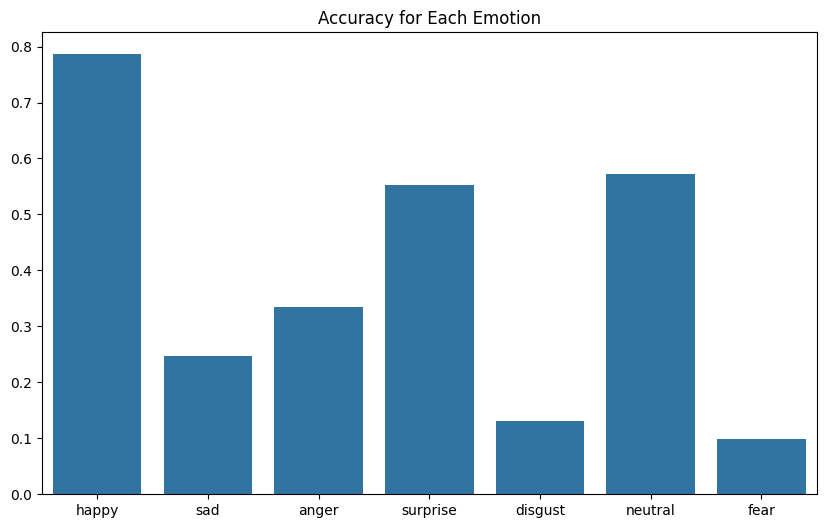

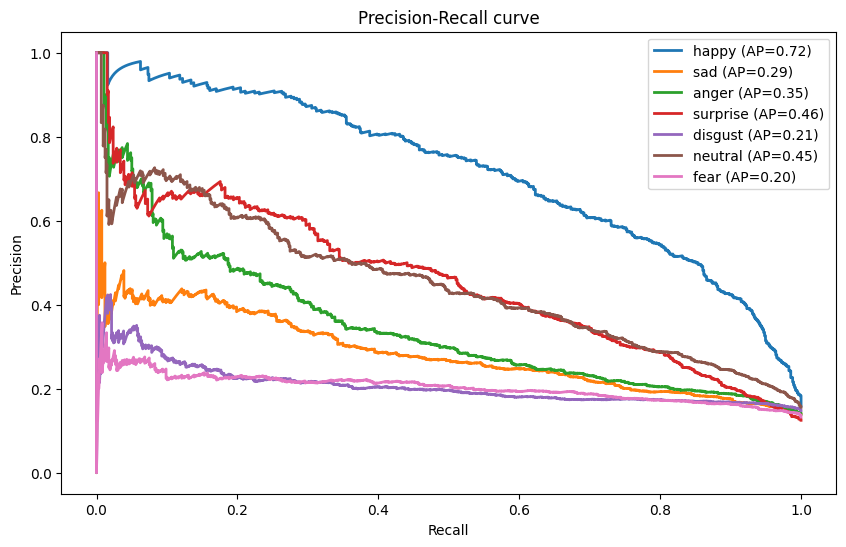

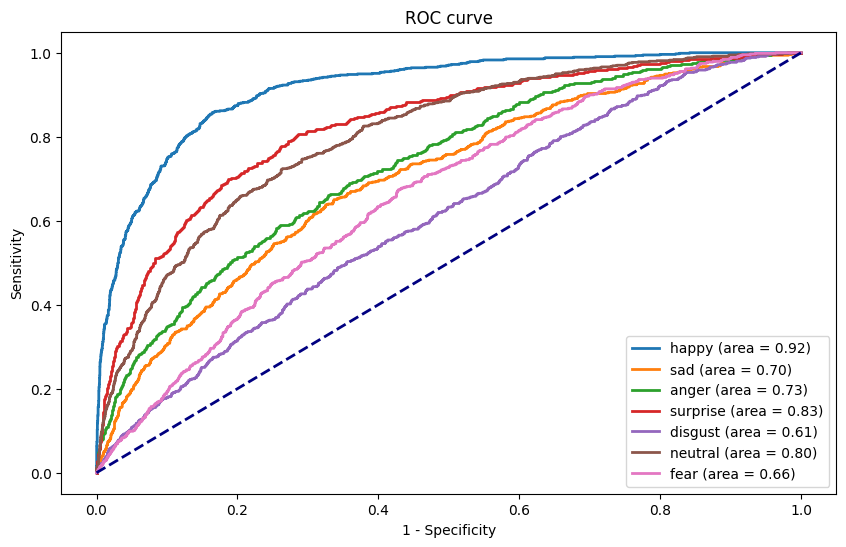

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, Dropout, LayerNormalization, MultiHeadAttention, GlobalAveragePooling1D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score, auc, precision_recall_curve, average_precision_score
import random

learning_rate_transformer = 5e-4

# 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}

model_name = 'Transformer Only'

# focal loss 정의
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)
    return focal_loss_fixed

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)
    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.cast(image, tf.float32) / 255.0
    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))
    return image, label

# 데이터셋 로딩 함수
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

# 데이터 로드
train_dataset = load_and_prepare_dataset("/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord", batch_size)
val_dataset = load_and_prepare_dataset("/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord", batch_size)
test_dataset = load_and_prepare_dataset("/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord", batch_size)

# ViT 구성 요소 정의
def mlp(x, hidden_units, dropout_rate):
    for units in hidden_units:
        x = Dense(units, activation='gelu')(x)
        x = Dropout(dropout_rate)(x)
    return x

def build_transformer_model(input_shape=(64, 64, 1), num_classes=7, patch_size=8, projection_dim=64, num_heads=4, transformer_layers=4):
    inputs = Input(shape=input_shape)
    x = tf.keras.layers.Conv2D(filters=projection_dim, kernel_size=patch_size, strides=patch_size, padding='valid')(inputs)
    x = tf.keras.layers.Reshape((-1, projection_dim))(x)

    for _ in range(transformer_layers):
        x1 = LayerNormalization(epsilon=1e-6)(x)
        attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=projection_dim)(x1, x1)
        x2 = Dropout(0.1)(attention_output)
        x = x + x2

        x1 = LayerNormalization(epsilon=1e-6)(x)
        x2 = mlp(x1, hidden_units=[projection_dim * 2, projection_dim], dropout_rate=0.1)
        x = x + x2

    x = LayerNormalization(epsilon=1e-6)(x)
    x = GlobalAveragePooling1D()(x)
    x = Dropout(0.3)(x)
    outputs = Dense(num_classes, activation='softmax', kernel_regularizer=l2(0.001))(x)

    return Model(inputs=inputs, outputs=outputs)

# 모델 생성 및 컴파일
transformer_model = build_transformer_model()
transformer_model.compile(
    optimizer=Adam(learning_rate=learning_rate_transformer),
    loss=focal_loss(),
    metrics=['accuracy']
)

# 콜백
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)

# 학습
train_dataset = train_dataset.shuffle(buffer_size=10000)
history = transformer_model.fit(
    x=train_dataset,
    epochs=epochs,
    validation_data=val_dataset,
    callbacks=[early_stopping, reduce_lr]
)

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 저장 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')

# 정확도/손실 그래프 저장
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f'Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig(accuracy_loss_path)

# 모델 평가
transformer_test_loss, transformer_test_accuracy = transformer_model.evaluate(test_dataset, verbose=1)
print("Test Loss:", transformer_test_loss)
print("Test Accuracy:", transformer_test_accuracy)

# 예측 결과 수집
transformer_test_images = []
y_test = []
for image, label in test_dataset:
    transformer_test_images.append(image)
    y_test.extend(label.numpy())

transformer_y_test_pred = transformer_model.predict([np.vstack(transformer_test_images)])
y_test = np.argmax(y_test, axis=1)
transformer_y_test_pred = np.argmax(transformer_y_test_pred, axis=1)

# 혼돈 행렬 시각화
cm = confusion_matrix(y_test, transformer_y_test_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 감정별 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    idx = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(np.array(y_test)[y_test == idx], np.array(transformer_y_test_pred)[y_test == idx])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title('Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어
precision = precision_score(y_test, transformer_y_test_pred, average='macro')
recall = recall_score(y_test, transformer_y_test_pred, average='macro')
f1 = f1_score(y_test, transformer_y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# ROC AUC
transformer_y_test_prob = transformer_model.predict([np.vstack(transformer_test_images)])
roc_auc = roc_auc_score(y_test, transformer_y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# PR Curve
precision_dict, recall_dict, average_precision_dict = {}, {}, {}
plt.figure(figsize=(10, 6))
for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(np.array(y_test) == i, transformer_y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(np.array(y_test) == i, transformer_y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2, label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# ROC Curve
fpr_dict, tpr_dict = {}, {}
plt.figure(figsize=(10, 6))
for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(np.array(y_test) == i, transformer_y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title('ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# PR/ROC Curve Data 저장
pr_curve_data = pd.DataFrame([{'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p} for emotion in emotion_labels for r, p in zip(recall_dict[emotion], precision_dict[emotion])])
roc_curve_data = pd.DataFrame([{'Model': model_name, 'Emotion': emotion, 'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]), 'FPR': f, 'TPR': t} for emotion in emotion_labels for f, t in zip(fpr_dict[emotion], tpr_dict[emotion])])
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {transformer_test_loss}\n")
    f.write(f"Test Accuracy: {transformer_test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

transformer_model.save(model_save_path_h5)
transformer_model.save(model_save_path_keras)


## CLIP

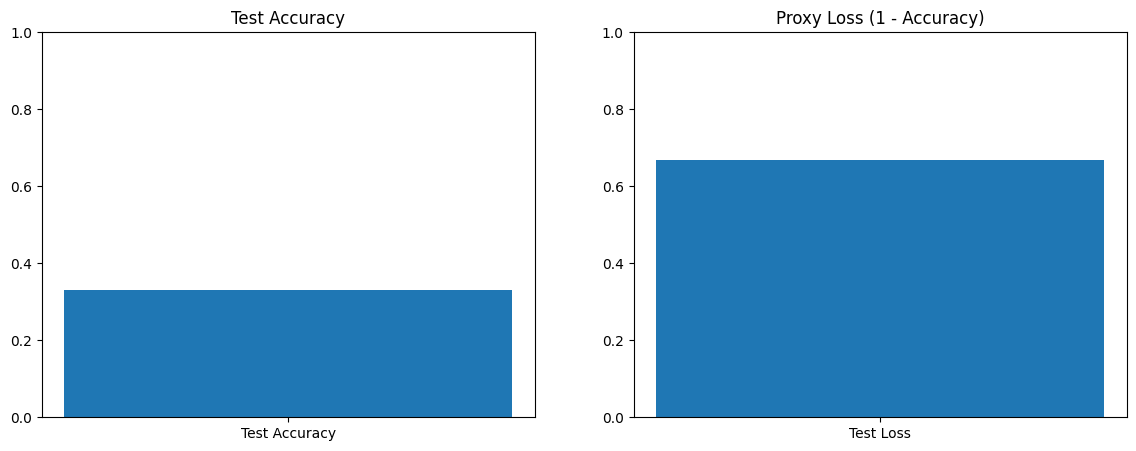

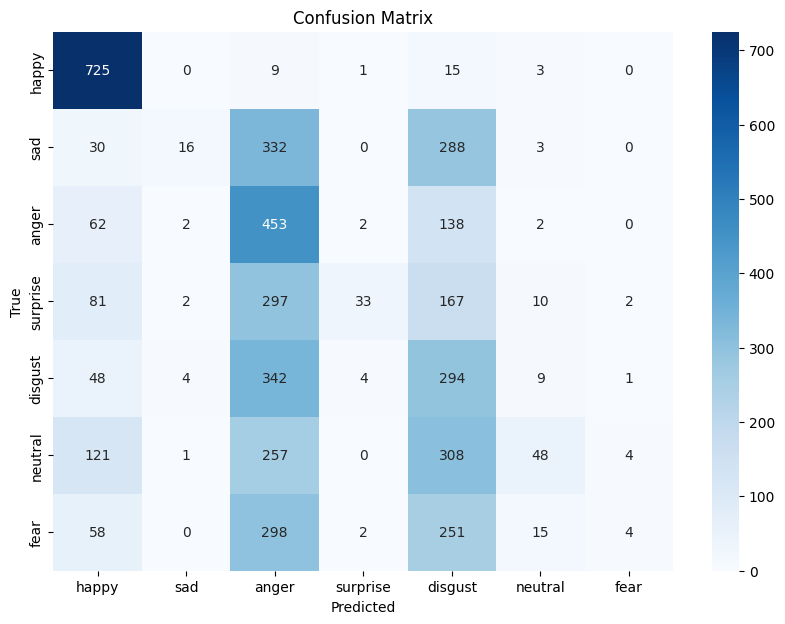

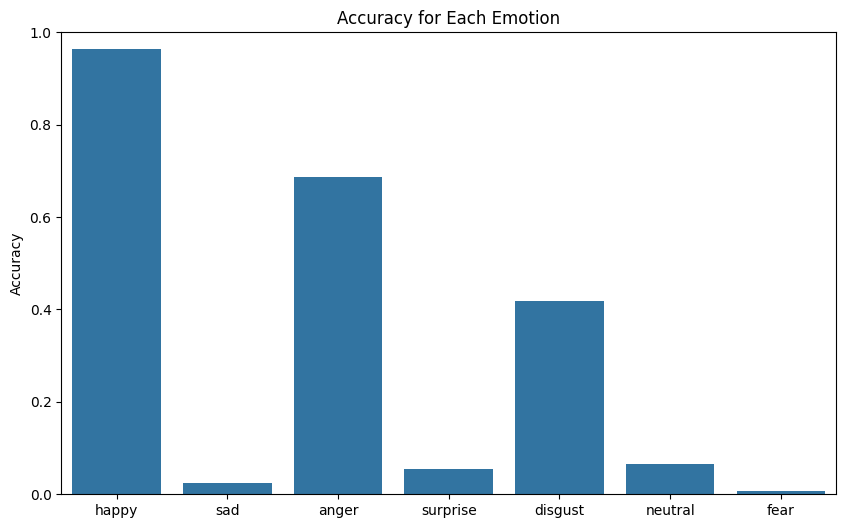

Test Accuracy: 0.3317
Accuracy for happy: 0.963
Accuracy for sad: 0.024
Accuracy for anger: 0.687
Accuracy for surprise: 0.056
Accuracy for disgust: 0.419
Accuracy for neutral: 0.065
Accuracy for fear: 0.006
Precision: 0.485
Recall: 0.317
F1 Score: 0.238
ROC AUC Score: 0.738


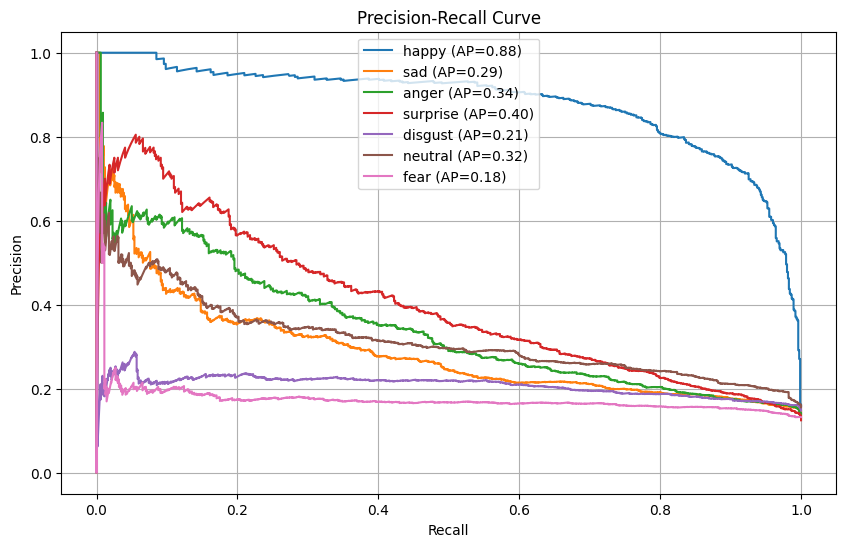

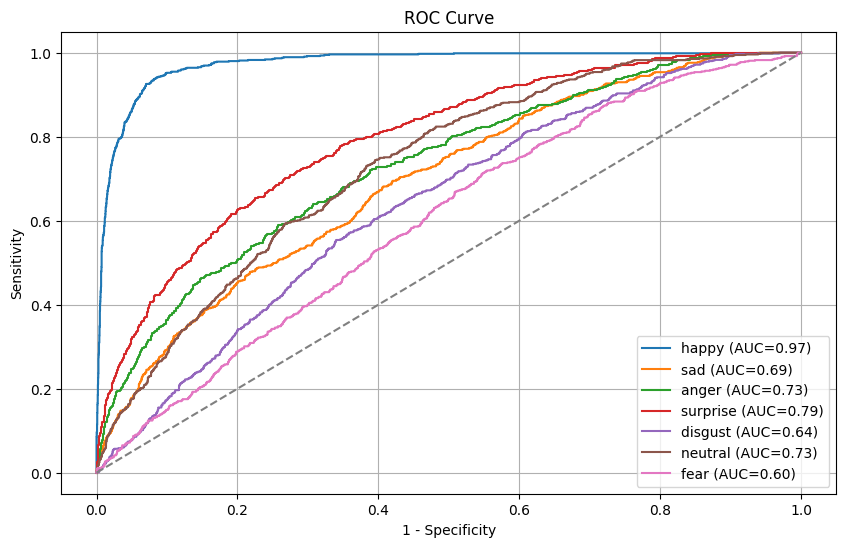

✅ CLIP 모델 평가 및 저장 완료.


In [ ]:
# ✅ CLIP-based Emotion Classifier using Hugging Face (Colab Ready)
# 📌 Source: https://huggingface.co/openai/clip-vit-base-patch32

!pip install transformers --quiet

import torch
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, precision_recall_curve, average_precision_score, roc_curve, auc
from transformers import CLIPProcessor, CLIPModel
from PIL import Image
import os

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}
label2emotion = {v: k for k, v in emotion_labels.items()}
texts = list(emotion_labels.keys())

model_name = "CLIP_Emotion"
drive_path = '/content/drive/MyDrive/FINAL'
os.makedirs(drive_path, exist_ok=True)

# 저장 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')

# CLIP 모델 로딩
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# TFRecord 파싱 함수
def parse_tfrecord_image_label(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed = tf.io.parse_single_example(tfrecord, features)
    image = tf.io.decode_jpeg(parsed["image"])
    label = parsed["label"]
    return image, label

def tfrecord_to_numpy_images_labels(tfrecord_path, limit=None):
    dataset = tf.data.TFRecordDataset(tfrecord_path).map(parse_tfrecord_image_label)
    images, labels = [], []
    for image, label in dataset.take(limit if limit else -1):
        image = tf.image.resize(image, [224, 224])
        image = tf.image.grayscale_to_rgb(tf.expand_dims(image, -1)) if image.shape[-1] == 1 else image
        images.append(Image.fromarray(np.uint8(image.numpy())))
        labels.append(label.numpy())
    return images, labels

# Load test set
images, y_true = tfrecord_to_numpy_images_labels("/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord")

# CLIP 추론 수행
inputs = clip_processor(text=texts, images=images, return_tensors="pt", padding=True)
with torch.no_grad():
    outputs = clip_model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1).cpu().numpy()
y_pred = np.argmax(probs, axis=1)

# 정확도/손실 그래프 저장
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.bar(["Test Accuracy"], [accuracy_score(y_true, y_pred)])
plt.ylim(0, 1)
plt.title("Test Accuracy")

plt.subplot(1, 2, 2)
plt.bar(["Test Loss"], [1 - accuracy_score(y_true, y_pred)])
plt.ylim(0, 1)
plt.title("Proxy Loss (1 - Accuracy)")

plt.savefig(accuracy_loss_path)
plt.show()

# 혼동 행렬
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=texts, yticklabels=texts)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.savefig(confusion_matrix_path)
plt.show()

# 감정별 정확도
emotion_accuracy_dict = {}
for i, emotion in enumerate(texts):
    correct = [pred for true, pred in zip(y_true, y_pred) if true == i]
    emotion_accuracy = accuracy_score([i]*len(correct), correct) if correct else 0.0
    emotion_accuracy_dict[emotion] = emotion_accuracy

plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title("Accuracy for Each Emotion")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.savefig(emotion_accuracy_path)
plt.show()

# 전체 지표
precision = precision_score(y_true, y_pred, average='macro')
recall = recall_score(y_true, y_pred, average='macro')
f1 = f1_score(y_true, y_pred, average='macro')
roc_auc = roc_auc_score(tf.keras.utils.to_categorical(y_true, num_classes=7), probs, multi_class='ovr')

print(f"Test Accuracy: {accuracy_score(y_true, y_pred):.4f}")
for emotion, acc in emotion_accuracy_dict.items():
    print(f"Accuracy for {emotion}: {acc:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1 Score: {f1:.3f}")
print(f"ROC AUC Score: {roc_auc:.3f}")

# PR Curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))
for i, emotion in enumerate(texts):
    precision_i, recall_i, _ = precision_recall_curve(np.array(y_true) == i, probs[:, i])
    average_precision_dict[emotion] = average_precision_score(np.array(y_true) == i, probs[:, i])
    precision_dict[emotion] = precision_i
    recall_dict[emotion] = recall_i
    plt.plot(recall_i, precision_i, label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid()
plt.savefig(precision_recall_curve_path)
plt.show()

# ROC Curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))
for i, emotion in enumerate(texts):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(np.array(y_true) == i, probs[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], label=f'{emotion} (AUC={auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title('ROC Curve')
plt.legend()
plt.grid()
plt.savefig(roc_curve_path)
plt.show()

# PR/ROC 데이터 저장
pr_data = []
for i, emotion in enumerate(texts):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        pr_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})
pd.DataFrame(pr_data).to_csv(pr_curve_data_path, index=False)

roc_data = []
for i, emotion in enumerate(texts):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        roc_data.append({'Model': model_name, 'Emotion': emotion, 'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]), 'FPR': f, 'TPR': t})
pd.DataFrame(roc_data).to_csv(roc_curve_data_path, index=False)

# 요약 저장
with open(summary_path, "w") as f:
    f.write(f"Test Accuracy: {accuracy_score(y_true, y_pred):.4f}\n")
    for emotion, acc in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {acc:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"ROC AUC Score: {roc_auc:.3f}\n")

print("✅ CLIP 모델 평가 및 저장 완료.")

## ViT (Hugging Face)

All PyTorch model weights were used when initializing TFViTModel.

All the weights of TFViTModel were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFViTModel for predictions without further training.


Epoch 1/100
   2219/Unknown 251s 96ms/step - accuracy: 0.3776 - loss: 0.2837

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2219/2219 ━━━━━━━━━━━━━━━━━━━━ 289s 113ms/step - accuracy: 0.3776 - loss: 0.2837 - val_accuracy: 0.4765 - val_loss: 0.2341 - learning_rate: 5.0000e-04
Epoch 2/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 228s 102ms/step - accuracy: 0.4693 - loss: 0.2336 - val_accuracy: 0.5002 - val_loss: 0.2264 - learning_rate: 5.0000e-04
Epoch 3/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 228s 102ms/step - accuracy: 0.4769 - loss: 0.2288 - val_accuracy: 0.5004 - val_loss: 0.2235 - learning_rate: 5.0000e-04
...
Epoch 21/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 227s 101ms/step - accuracy: 0.4924 - loss: 0.2215 - val_accuracy: 0.5229 - val_loss: 0.2151 - learning_rate: 2.5000e-04
Epoch 22/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 228s 101ms/step - accuracy: 0.4955 - loss: 0.2210 - val_accuracy: 0.5247 - val_loss: 0.2153 - learning_rate: 2.5000e-04
Epoch 23/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 228s 101ms/step - accuracy: 0.4974 - loss: 0.2213 - val_accuracy: 0.5164 - val_loss: 0.2151 - learning_rate: 2.5000e-04
Epoch 24/100
2219/2219 ━━━━

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: image
Received: inputs=('Tensor(shape=(32, 64, 64, 1))',)
  warnings.warn(msg)


148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: image
Received: inputs=('Tensor(shape=(None, 64, 64, 1))',)
  warnings.warn(msg)


149/149 ━━━━━━━━━━━━━━━━━━━━ 24s 132ms/step
Accuracy for happy: 0.92
Accuracy for sad: 0.49
Accuracy for anger: 0.52
Accuracy for surprise: 0.60
Accuracy for disgust: 0.24
Accuracy for neutral: 0.69
Accuracy for fear: 0.16
Precision: 0.51
Recall: 0.52
F1 Score: 0.51
ViT_TF ROC AUC Score: 0.84


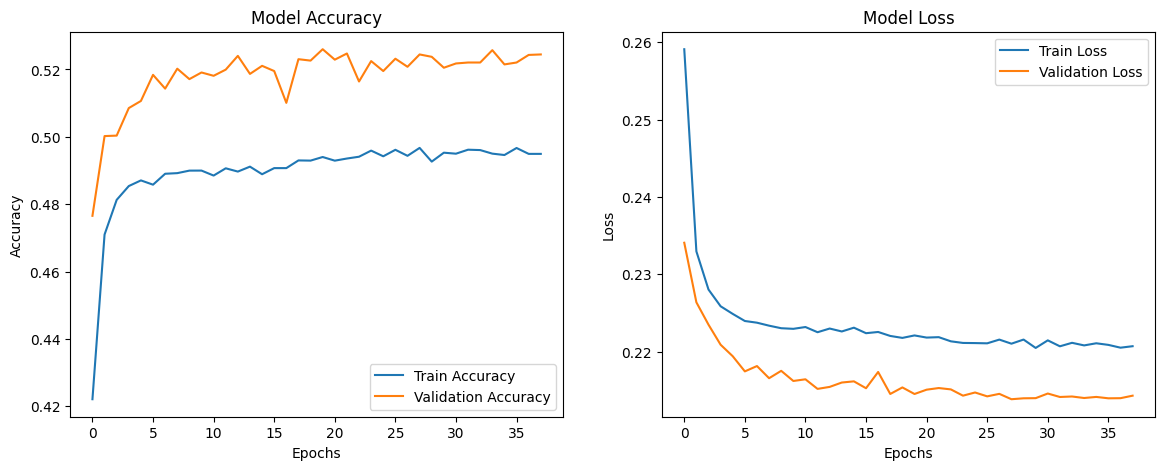

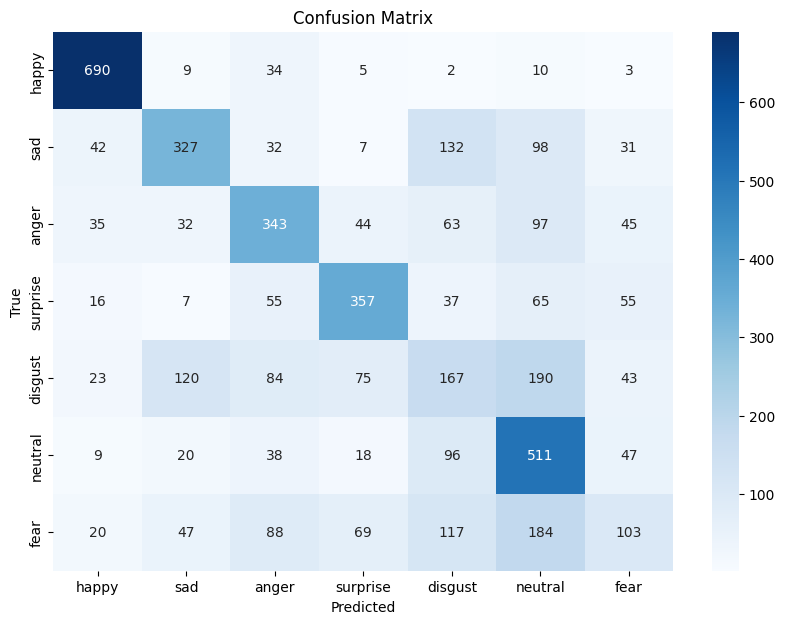

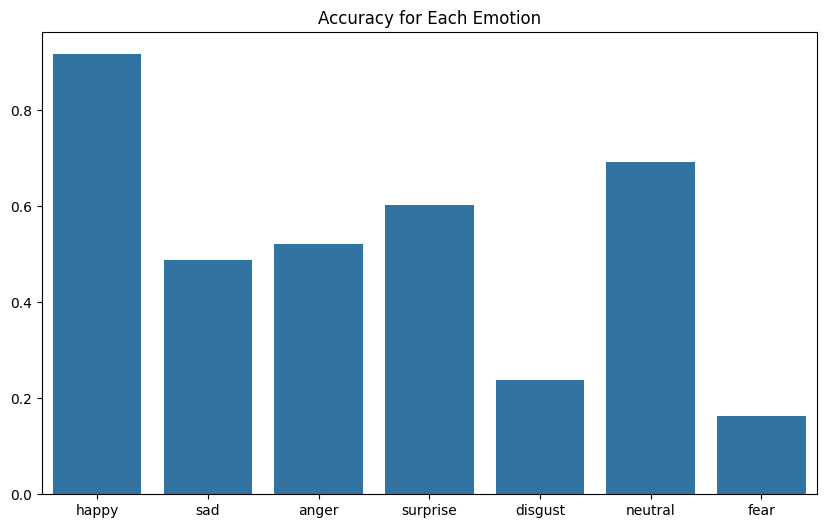

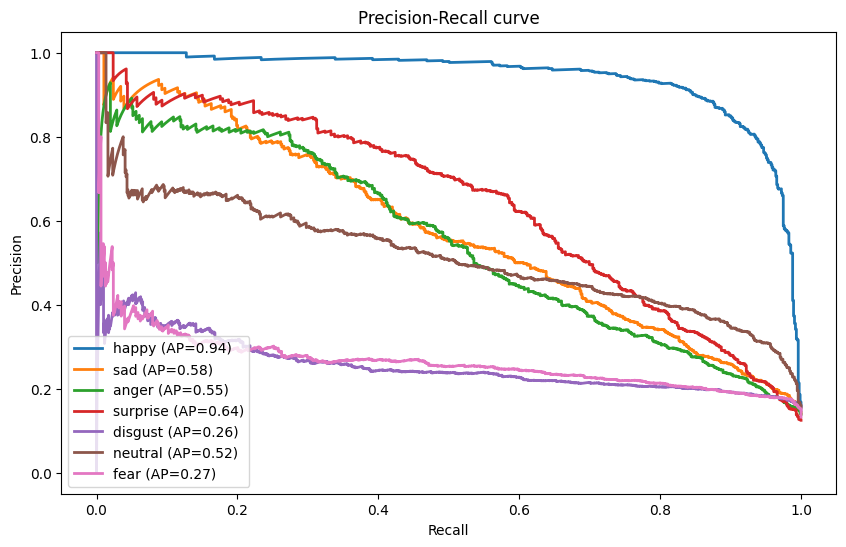

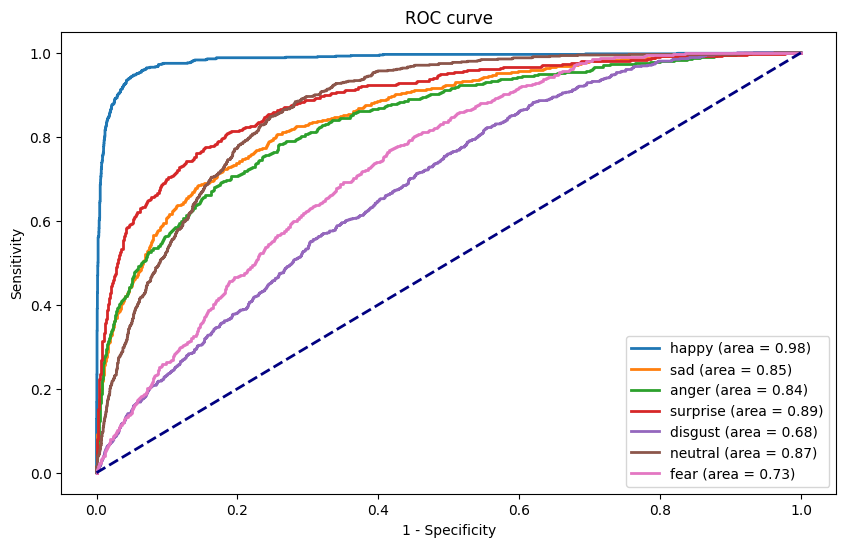

In [14]:
# 설치 (최초 1회만 필요)
!pip install -q transformers

# 시드 설정
import tensorflow as tf
import numpy as np
import random

seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

# 하이퍼파라미터
epochs = 100
batch_size = 32
patience_es = 10
factor_lr = 0.5
patience_lr = 5
learning_rate_transformer = 5e-4

# 기본 import
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score, auc, precision_recall_curve, average_precision_score

# Hugging Face import
from transformers import TFAutoModel, AutoConfig

# 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}

model_name = 'ViT_TF'

# focal loss 정의
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)
    return focal_loss_fixed

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)
    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.cast(image, tf.float32) / 255.0
    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))
    return image, label

def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

# 데이터 로드
train_dataset = load_and_prepare_dataset("/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord", batch_size)
val_dataset = load_and_prepare_dataset("/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord", batch_size)
test_dataset = load_and_prepare_dataset("/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord", batch_size)

# ViT 모델 로딩
vit_model_name = "google/vit-base-patch16-224-in21k"
vit_backbone = TFAutoModel.from_pretrained(vit_model_name)

# 커스텀 래퍼
class VitWrapper(tf.keras.layers.Layer):
    def __init__(self, vit_model, **kwargs):
        super().__init__(**kwargs)
        self.vit_model = vit_model

    def call(self, inputs, **kwargs):
        outputs = self.vit_model({"pixel_values": inputs})
        return outputs.last_hidden_state

# 최종 모델 정의 함수
def build_vit_based_model(vit_model, num_classes=7):
    input_image = tf.keras.Input(shape=(64, 64, 1), name='image')

    # Grayscale → RGB 복제
    x = tf.keras.layers.Concatenate()([input_image] * 3)

    # Resize to 224x224
    x = tf.keras.layers.Resizing(224, 224)(x)  # (B, 224, 224, 3)

    # Permute axes: (B, H, W, C) -> (B, C, H, W)
    x = tf.keras.layers.Permute((3, 1, 2))(x)

    # ViT model 통과
    x = VitWrapper(vit_model)(x)

    x = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    output = tf.keras.layers.Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs=input_image, outputs=output)
    return model




# 모델 생성 및 컴파일
model = build_vit_based_model(vit_backbone)
model.compile(
    optimizer=Adam(learning_rate=learning_rate_transformer),
    loss=focal_loss(),
    metrics=['accuracy']
)

# 콜백
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)

# 학습
train_dataset = train_dataset.shuffle(buffer_size=10000)
history = model.fit(
    x=train_dataset,
    epochs=epochs,
    validation_data=val_dataset,
    callbacks=[early_stopping, reduce_lr]
)

# 저장 경로 설정
drive_path = '/content/drive/MyDrive/FINAL_ViT'
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')

# 정확도/손실 그래프
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f'Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig(accuracy_loss_path)

# 평가
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 예측
test_images = []
y_test = []
for image, label in test_dataset:
    test_images.append(image)
    y_test.extend(label.numpy())

y_pred = model.predict([np.vstack(test_images)])
y_test = np.argmax(y_test, axis=1)
y_pred_label = np.argmax(y_pred, axis=1)

# 혼돈 행렬
cm = confusion_matrix(y_test, y_pred_label)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 감정별 정확도
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    idx = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(np.array(y_test)[y_test == idx], np.array(y_pred_label)[y_test == idx])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title('Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1
precision = precision_score(y_test, y_pred_label, average='macro')
recall = recall_score(y_test, y_pred_label, average='macro')
f1 = f1_score(y_test, y_pred_label, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# ROC AUC
roc_auc = roc_auc_score(y_test, y_pred, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# PR Curve
precision_dict, recall_dict, average_precision_dict = {}, {}, {}
plt.figure(figsize=(10, 6))
for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(np.array(y_test) == i, y_pred[:, i])
    average_precision_dict[emotion] = average_precision_score(np.array(y_test) == i, y_pred[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2, label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# ROC Curve
fpr_dict, tpr_dict = {}, {}
plt.figure(figsize=(10, 6))
for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(np.array(y_test) == i, y_pred[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title('ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# PR/ROC 데이터 저장
pr_curve_data = pd.DataFrame([{'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p} for emotion in emotion_labels for r, p in zip(recall_dict[emotion], precision_dict[emotion])])
roc_curve_data = pd.DataFrame([{'Model': model_name, 'Emotion': emotion, 'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]), 'FPR': f, 'TPR': t} for emotion in emotion_labels for f, t in zip(fpr_dict[emotion], tpr_dict[emotion])])
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model.save(model_save_path_h5)
model.save(model_save_path_keras)
